# Лабораторная работа по распознаванию цифр с использованием набора данных MNIST

**Введение.** В данной лабораторной работе студентам предлагается рассмотреть задачу распознавания рукописных цифр на основе набора данных MNIST. Для обучения и оценки модели используется библиотека PyTorch.

**Теоретическое обоснование.** Задача распознавания рукописных цифр является классической задачей классификации изображений в области машинного обучения. В рамках данной лабораторной работы мы будем использовать простую полносвязную нейронную сеть (Multilayer Perceptron, MLP) для решения этой задачи.

![title](mlp.png)

**Описание данных.** Набор данных MNIST состоит из 70 000 изображений размером 28×28 пикселей, каждое из которых представляет собой рукописную цифру от 0 до 9. Изображения представлены в градациях серого: цифра изображена светлым штрихом на чёрном фоне, значение 0 соответствует чёрному цвету, а 255 — белому. При загрузке преобразование `ToTensor` переводит значения яркости в отрезок $[0, 1]$. Данные разделены на две части: обучающую выборку из 60 000 изображений и тестовую выборку из 10 000 изображений. Цифры в MNIST нормированы: каждая вписана в квадрат 20×20 пикселей и помещена в изображение 28×28 так, чтобы центр масс штриха совпадал с центром изображения.

**Описание метрик.** В качестве метрик для оценки модели мы будем использовать точность (accuracy) и матрицу ошибок (confusion matrix). Точность представляет собой долю правильно классифицированных изображений, а матрица ошибок показывает, какие классы были правильно и неправильно распознаны.

**Описание модели.** Мы будем использовать полносвязную нейронную сеть с одним скрытым слоем из 128 нейронов. В качестве функции активации на скрытом слое используется ReLU. Выходной слой выдаёт 10 чисел — ненормированных оценок классов (логитов). Функция softmax переводит их в вероятности классов. В PyTorch она уже входит в функцию потерь `nn.CrossEntropyLoss`, которая вычисляет перекрёстную энтропию по логитам. Поэтому в самой модели softmax не применяется: повторное применение искажает градиенты и сильно замедляет обучение. Вероятности при необходимости получают отдельно, вызовом `F.softmax`. В качестве алгоритма оптимизации используется стохастический градиентный спуск (SGD).

**Установка библиотек:**

```
pip install opencv-python
pip3 install torch torchvision torchaudio
pip install -U scikit-learn
```

Изображения `mlp.png`, `ex1.jpg` и `ex2.jpg` хранятся в репозитории через Git LFS. Если репозиторий клонирован без Git LFS, выполните `git lfs install` и `git lfs pull`.

## Импорт необходимых библиотек

In [1]:
import copy
import numpy as np
import matplotlib.pyplot as plt
import cv2
import torch
import torchvision
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split
from torchvision.transforms import ToTensor
from sklearn.metrics import confusion_matrix, accuracy_score

# Фиксируем генераторы случайных чисел, чтобы результаты повторялись от запуска к запуску
SEED = 2026
torch.manual_seed(SEED)
np.random.seed(SEED)

## Загрузка данных

При первом запуске набор MNIST загружается в каталог `data/` рядом с блокнотом.

In [2]:
train_full = torchvision.datasets.MNIST(root='./data', train=True, transform=ToTensor(), download=True)
test_data = torchvision.datasets.MNIST(root='./data', train=False, transform=ToTensor(), download=True)

100%|██████████| 9.91M/9.91M [00:02<00:00, 4.58MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 251kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 2.10MB/s]
100%|██████████| 4.54k/4.54k [00:00<?, ?B/s]


## Разделение данных на обучающую, валидационную и тестовую выборки

Из 60 000 обучающих изображений 10 000 откладываются для валидации: по ним выбирается лучшая эпоха обучения. Тестовая выборка используется только для итоговой оценки.

In [3]:
train_data, val_data = random_split(train_full, [50000, 10000],
                                    generator=torch.Generator().manual_seed(SEED))
train_loader = DataLoader(train_data, batch_size=64, shuffle=True,
                          generator=torch.Generator().manual_seed(SEED))
val_loader = DataLoader(val_data, batch_size=64, shuffle=False)
test_loader = DataLoader(test_data, batch_size=64, shuffle=False)

## Описание модели

In [4]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(28*28, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = x.view(-1, 28*28)
        x = F.relu(self.fc1(x))
        return self.fc2(x)          # логиты; softmax входит в nn.CrossEntropyLoss

## Инициализация модели и определение функций обучения и оценки

Функции возвращают среднее значение функции потерь по всем примерам. Функция оценки дополнительно возвращает точность.

In [5]:
model = MLP()
optimizer = optim.SGD(model.parameters(), lr=0.01)

def train_epoch(model, data_loader, optimizer, loss_fn):
    model.train()
    total_loss, n = 0.0, 0
    for X, Y in data_loader:
        optimizer.zero_grad()
        loss = loss_fn(model(X), Y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(Y)
        n += len(Y)
    return total_loss / n

def evaluate_model(model, data_loader, loss_fn):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for X, Y in data_loader:
            logits = model(X)
            total_loss += loss_fn(logits, Y).item() * len(Y)
            correct += (logits.argmax(dim=1) == Y).sum().item()
            n += len(Y)
    return total_loss / n, correct / n

## Обучение

После каждой эпохи вычисляются потери и точность на валидационной выборке. Сохраняется состояние модели с наибольшей валидационной точностью; именно оно используется для итоговой оценки.

In [6]:
num_epochs = 20
loss_fn = nn.CrossEntropyLoss()
history = {'train_loss': [], 'val_loss': [], 'val_acc': []}
best_acc, best_epoch, best_state = 0.0, 0, None

for epoch in range(num_epochs):
    train_loss = train_epoch(model, train_loader, optimizer, loss_fn)
    val_loss, val_acc = evaluate_model(model, val_loader, loss_fn)
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    if val_acc > best_acc:
        best_acc, best_epoch = val_acc, epoch + 1
        best_state = copy.deepcopy(model.state_dict())
    print(f"Эпоха {epoch+1:2d}: потери (обуч.) {train_loss:.4f}, "
          f"потери (валид.) {val_loss:.4f}, точность (валид.) {val_acc:.4f}")

model.load_state_dict(best_state)
print(f"\nВыбрана эпоха {best_epoch}: точность на валидационной выборке {best_acc:.4f}")

Эпоха  1: потери (обуч.) 1.3726, потери (валид.) 0.7075, точность (валид.) 0.8396
Эпоха  2: потери (обуч.) 0.5442, потери (валид.) 0.4745, точность (валид.) 0.8767
Эпоха  3: потери (обуч.) 0.4165, потери (валид.) 0.4100, точность (валид.) 0.8868
Эпоха  4: потери (обуч.) 0.3686, потери (валид.) 0.3779, точность (валид.) 0.8941
Эпоха  5: потери (обуч.) 0.3416, потери (валид.) 0.3564, точность (валид.) 0.8985
Эпоха  6: потери (обуч.) 0.3227, потери (валид.) 0.3433, точность (валид.) 0.9012
Эпоха  7: потери (обуч.) 0.3083, потери (валид.) 0.3296, точность (валид.) 0.9071
Эпоха  8: потери (обуч.) 0.2961, потери (валид.) 0.3190, точность (валид.) 0.9076
Эпоха  9: потери (обуч.) 0.2855, потери (валид.) 0.3107, точность (валид.) 0.9114
Эпоха 10: потери (обуч.) 0.2759, потери (валид.) 0.3022, точность (валид.) 0.9127
Эпоха 11: потери (обуч.) 0.2668, потери (валид.) 0.2921, точность (валид.) 0.9158
Эпоха 12: потери (обуч.) 0.2585, потери (валид.) 0.2843, точность (валид.) 0.9181
Эпоха 13: потери

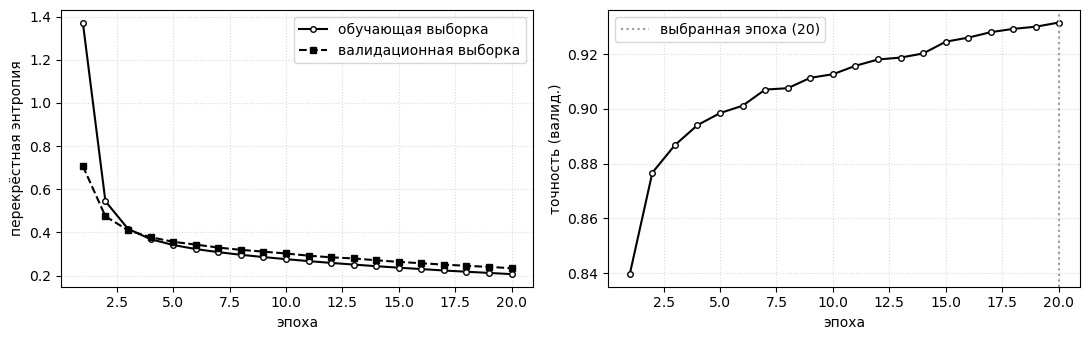

In [7]:
epochs = np.arange(1, num_epochs + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(epochs, history['train_loss'], 'k-o', ms=4, mfc='white', label='обучающая выборка')
axes[0].plot(epochs, history['val_loss'], 'k--s', ms=4, label='валидационная выборка')
axes[0].set_xlabel('эпоха'); axes[0].set_ylabel('перекрёстная энтропия'); axes[0].legend()
axes[1].plot(epochs, history['val_acc'], 'k-o', ms=4, mfc='white')
axes[1].axvline(best_epoch, color='0.6', ls=':', label=f'выбранная эпоха ({best_epoch})')
axes[1].set_xlabel('эпоха'); axes[1].set_ylabel('точность (валид.)'); axes[1].legend()
for ax in axes: ax.grid(color='0.85', ls=':')
plt.tight_layout(); plt.show()

## Оценка полученной модели

In [8]:
def predict(model, loader):
    model.eval()
    all_preds = []
    with torch.no_grad():
        for X, _ in loader:
            all_preds.append(model(X).argmax(dim=1))
    return torch.cat(all_preds).numpy()

Y_true = test_data.targets.numpy()
Y_pred = predict(model, test_loader)          # порядок совпадает с test_data: shuffle=False
accuracy = accuracy_score(Y_true, Y_pred)
cm = confusion_matrix(Y_true, Y_pred)
print(f"Точность на тестовой выборке: {accuracy:.4f}")
print("Матрица ошибок (строки — истинные цифры, столбцы — распознанные):")
print(cm)

Точность на тестовой выборке: 0.9403
Матрица ошибок (строки — истинные цифры, столбцы — распознанные):
[[ 963    0    1    3    0    3    7    1    2    0]
 [   0 1114    2    2    1    1    4    2    9    0]
 [   6    3  959   12    8    2   10    9   19    4]
 [   2    1   15  940    1   18    1   11   14    7]
 [   1    2    3    1  927    0   10    3    5   30]
 [   9    3    4   24    7  800   13    4   20    8]
 [  10    3    4    0    9   10  919    1    2    0]
 [   2    7   24    4    4    1    0  961    2   23]
 [   6    5    4   15   10   17   10    9  891    7]
 [   9    7    1    9   33    5    1   10    5  929]]


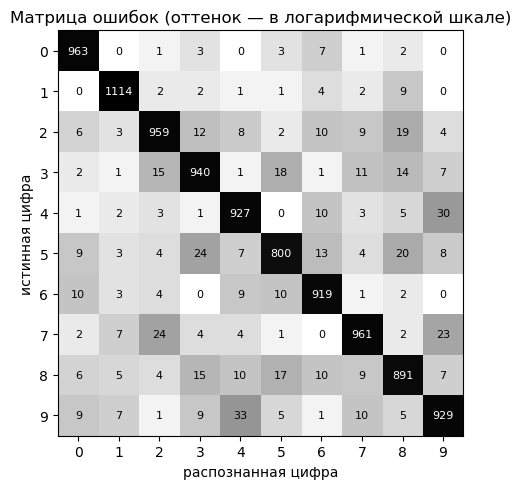

In [9]:
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(np.log10(cm + 1), cmap='Greys')
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=8,
                color='white' if cm[i, j] > cm.max() / 3 else 'black')
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xlabel('распознанная цифра'); ax.set_ylabel('истинная цифра')
ax.set_title('Матрица ошибок (оттенок — в логарифмической шкале)')
plt.tight_layout(); plt.show()

## Визуализация

In [10]:
def visualize_predictions(images, labels, preds, num_samples=10, title=None):
    idxs = np.random.choice(len(images), size=min(num_samples, len(images)), replace=False)
    fig, axes = plt.subplots(1, len(idxs), figsize=(15, 2.6))
    for i, ax in zip(idxs, np.atleast_1d(axes)):
        ax.imshow(images[i].numpy().squeeze(), cmap='gray')
        ax.set_title(f"{preds[i]} (верно: {labels[i]})", fontsize=10)
        ax.axis('off')
    if title: fig.suptitle(title)
    plt.show()

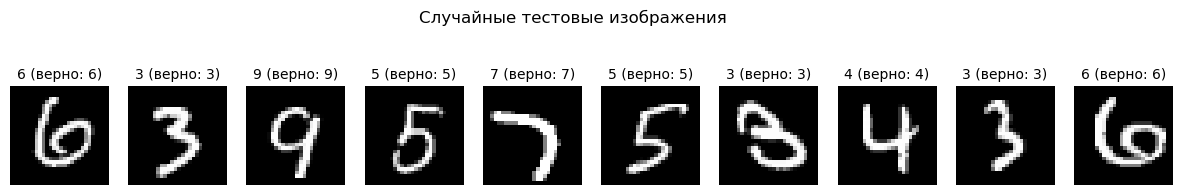

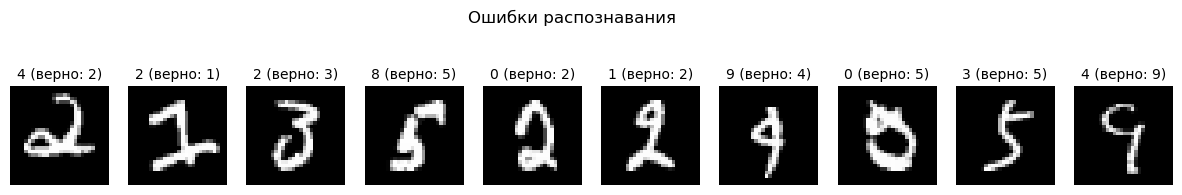

In [11]:
# Случайные изображения из первого пакета тестовой выборки
test_images, test_labels = next(iter(test_loader))
model.eval()
with torch.no_grad():
    batch_preds = model(test_images).argmax(dim=1).numpy()
visualize_predictions(test_images, test_labels.numpy(), batch_preds, title='Случайные тестовые изображения')

# Изображения, на которых сеть ошиблась
wrong = np.flatnonzero(Y_pred != Y_true)
sel = np.random.choice(wrong, size=min(10, len(wrong)), replace=False)
wrong_images = torch.stack([test_data[k][0] for k in sel])
visualize_predictions(wrong_images, Y_true[sel], Y_pred[sel], title='Ошибки распознавания')

### Распознавание собственных изображений

Сеть обучена на изображениях, подготовленных определённым образом, и собственное изображение нужно привести к тому же виду:

1. перевести в оттенки серого и бинаризовать так, чтобы цифра стала белой на чёрном фоне (порог выбирается методом Оцу);
2. вырезать прямоугольник, содержащий цифру, и вписать его в квадрат 20×20 с сохранением пропорций;
3. поместить результат в изображение 28×28 и сдвинуть так, чтобы центр масс штриха оказался в центре;
4. перевести яркость в отрезок $[0, 1]$, как это делает `ToTensor` для данных MNIST.

Если пропустить последний шаг и подать на вход значения от 0 до 255, сеть получит входы в 255 раз больше, чем при обучении, и её ответ станет непредсказуемым. Если сжать до 28×28 всё изображение целиком, цифра окажется меньше или иной формы, чем в обучающих данных.

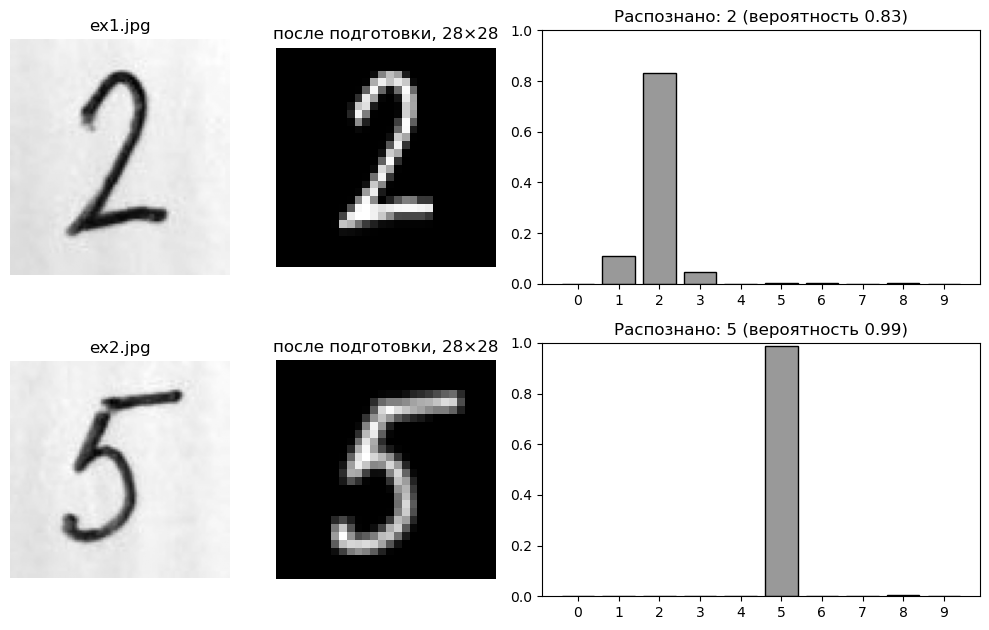

In [12]:
def prepare_digit(path):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(f"Не удалось прочитать {path}. Если репозиторий клонирован "
                                "без Git LFS, выполните git lfs install и git lfs pull.")
    # 1. Цифра — белая на чёрном фоне (тёмные чернила на светлой бумаге инвертируются)
    _, bw = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    ys, xs = np.nonzero(bw)
    if xs.size == 0:
        raise ValueError(f"На изображении {path} не найдена цифра")
    # 2. Вырезаем цифру и вписываем её в квадрат 20x20
    digit = bw[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    h, w = digit.shape
    s = 20.0 / max(h, w)
    digit = cv2.resize(digit, (max(1, round(w * s)), max(1, round(h * s))), interpolation=cv2.INTER_AREA)
    # 3. Помещаем в изображение 28x28 и совмещаем центр масс с центром
    canvas = np.zeros((28, 28), np.float32)
    h, w = digit.shape
    y0, x0 = (28 - h) // 2, (28 - w) // 2
    canvas[y0:y0 + h, x0:x0 + w] = digit
    m = cv2.moments(canvas)
    if m['m00'] > 0:
        cx, cy = m['m10'] / m['m00'], m['m01'] / m['m00']
        shift = np.float32([[1, 0, 13.5 - cx], [0, 1, 13.5 - cy]])
        canvas = cv2.warpAffine(canvas, shift, (28, 28))
    # 4. Яркость в отрезке [0, 1], как после ToTensor
    return torch.from_numpy(np.clip(canvas, 0, 255) / 255.0).float()

files = ['ex1.jpg', 'ex2.jpg']
fig, axes = plt.subplots(len(files), 3, figsize=(10, 3.2 * len(files)),
                         gridspec_kw={'width_ratios': [1, 1, 2]})
model.eval()
for row, path in zip(np.atleast_2d(axes), files):
    x = prepare_digit(path)
    with torch.no_grad():
        probs = F.softmax(model(x.unsqueeze(0)), dim=1)[0].numpy()
    row[0].imshow(cv2.imread(path, cv2.IMREAD_GRAYSCALE), cmap='gray'); row[0].set_title(path)
    row[1].imshow(x.numpy(), cmap='gray'); row[1].set_title('после подготовки, 28×28')
    row[2].bar(range(10), probs, color='0.6', edgecolor='black')
    row[2].set_xticks(range(10)); row[2].set_ylim(0, 1)
    row[2].set_title(f'Распознано: {probs.argmax()} (вероятность {probs.max():.2f})')
    row[0].axis('off'); row[1].axis('off')
plt.tight_layout(); plt.show()